# Track Linearization: Working with 1D Environments

**Estimated time**: 25-30 minutes

**Prerequisites**: [01: basics](01_introduction_basics.ipynb), [02: layouts](02_layout_engines.ipynb), [04: regions](04_regions_of_interest.ipynb).

## Learning Objectives

By the end of this notebook, you will be able to:

- Understand when and why to use 1D linearization
- Create linearized track environments with GraphLayout
- Convert between N-D position coordinates and 1D linear position
- Work with a branched plus-maze graph
- Understand the difference between 1D and N-D environments
- Combine linearized coordinates and explicit labels for directional neural analysis


## Why 1D Linearization?

Many experiments use track-based environments where movement is constrained to specific paths:

- **Linear tracks**: Simple back-and-forth running
- **W-tracks / Z-tracks**: Alternation tasks
- **Plus mazes**: Four-arm radial structures
- **Figure-8 mazes**: Continuous alternation
- **T-mazes**: Left/right choice tasks

For these environments, **linearization** maps 2D positions onto a 1D track coordinate. This is essential for:

- **Direction-conditioned analysis**: Combine track coordinates with explicit journey labels
- **Place field analysis**: Better capture spatially-tuned neurons on tracks
- **Sequence detection**: Identify replay and theta sequences
- **Directional coding**: Combine track geometry with explicit movement labels

`GraphLayout` supplies coordinates and connectivity. Trial and direction
labels remain explicit inputs to a directional analysis.

## Setup

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from neurospatial import Environment

np.random.seed(42)
# Shared styling (Okabe-Ito palette, consistent figure / font sizes)
import sys
from pathlib import Path

_here = (
    str(Path(__file__).resolve().parent) if "__file__" in globals() else str(Path.cwd())
)
if _here not in sys.path:
    sys.path.insert(0, _here)
from _style import apply_style

apply_style(figsize=(14, 10), font_size=11)

## Example 1: Simple Linear Track

Let's start with the simplest case: a straight linear track.

In [2]:
# Create position data for a linear track (back and forth)
track_length = 100.0  # cm
n_laps = 5
samples_per_lap = 200
n_samples = n_laps * samples_per_lap

# Position along track (oscillates back and forth)
t = np.linspace(0, n_laps * 2 * np.pi, n_samples)
x_position = (np.sin(t) + 1) * 50  # Oscillates between 0 and 100

# Y position is constant (straight track at y=0)
y_position = np.zeros_like(x_position)

# Add small noise
y_position += np.random.randn(n_samples) * 0.5

linear_track_data = np.column_stack([x_position, y_position])

print(f"Generated {n_samples} samples for linear track")
print(
    f"Track extent: X=[{x_position.min():.1f}, {x_position.max():.1f}], Y=[{y_position.min():.1f}, {y_position.max():.1f}]"
)

Generated 1000 samples for linear track
Track extent: X=[0.0, 100.0], Y=[-1.6, 1.9]


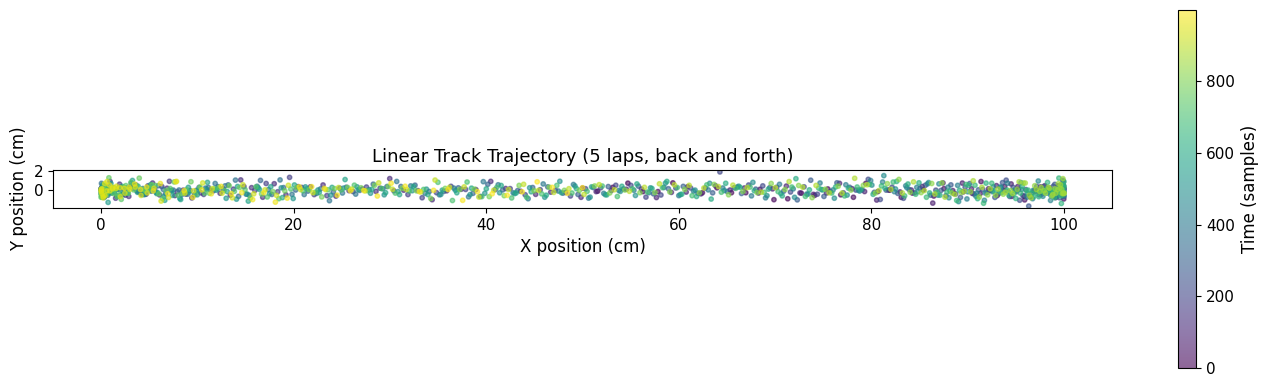

In [3]:
# Visualize the trajectory
fig, ax = plt.subplots(figsize=(14, 4))

scatter = ax.scatter(
    linear_track_data[:, 0],
    linear_track_data[:, 1],
    c=np.arange(n_samples),
    cmap="viridis",
    s=10,
    alpha=0.6,
)

ax.set_xlabel("X position (cm)")
ax.set_ylabel("Y position (cm)")
ax.set_title("Linear Track Trajectory (5 laps, back and forth)")
ax.set_aspect("equal")
plt.colorbar(scatter, ax=ax, label="Time (samples)")
plt.tight_layout()
plt.show()

### Creating a Linearized Environment

To create a 1D linearized environment, use `Environment.from_graph()`. This requires the `track-linearization` package.

**Note**: The `from_graph()` method automatically handles track linearization for you.

In [4]:
# For a linear track, create a simple graph with two nodes (endpoints) and one edge
linear_track_graph = nx.Graph()
linear_track_graph.add_node(0, pos=(0.0, 0.0))
linear_track_graph.add_node(1, pos=(100.0, 0.0))
linear_track_graph.add_edge(0, 1, edge_id=0)

# Add distance attribute to edge (required by GraphLayout)
for u, v in linear_track_graph.edges():
    pos_u = np.array(linear_track_graph.nodes[u]["pos"])
    pos_v = np.array(linear_track_graph.nodes[v]["pos"])
    linear_track_graph.edges[u, v]["distance"] = np.linalg.norm(pos_v - pos_u)

# Define edge order (list of edges to traverse)
edge_order = [(0, 1)]

# Create 1D linearized environment
env_1d = Environment.from_graph(
    graph=linear_track_graph,
    edge_order=edge_order,
    edge_spacing=0.0,  # No spacing between edges for single edge
    bin_size=5.0,  # 5 cm bins along track
    name="LinearTrack",
)
env_1d.units = "cm"

print("1D Environment Created!")
print(f"Is 1D: {env_1d.is_linearized_track}")
print(f"Number of bins: {env_1d.n_bins}")
print(f"Layout type: {env_1d.layout_type}")

1D Environment Created!
Is 1D: True
Number of bins: 20
Layout type: Graph


### Understanding 1D vs 2D Environments

The key difference:

- **2D/N-D Environment**: Bins represent regions in physical space
- **GraphLayout Environment**: Bins represent locations along track edges

**Critical insight**: Revisiting the same point on this single-edge track gives the same coordinate and bin in either direction. Linearization describes geometry; direction-specific fields also need explicit trial or movement labels. Branch assignment on more complex graphs depends on the graph and projection settings.
Graph environments retain embedded 2D bin centers for geometry and plotting;
use `to_linear(env.bin_centers)` to obtain the 1D track coordinates.

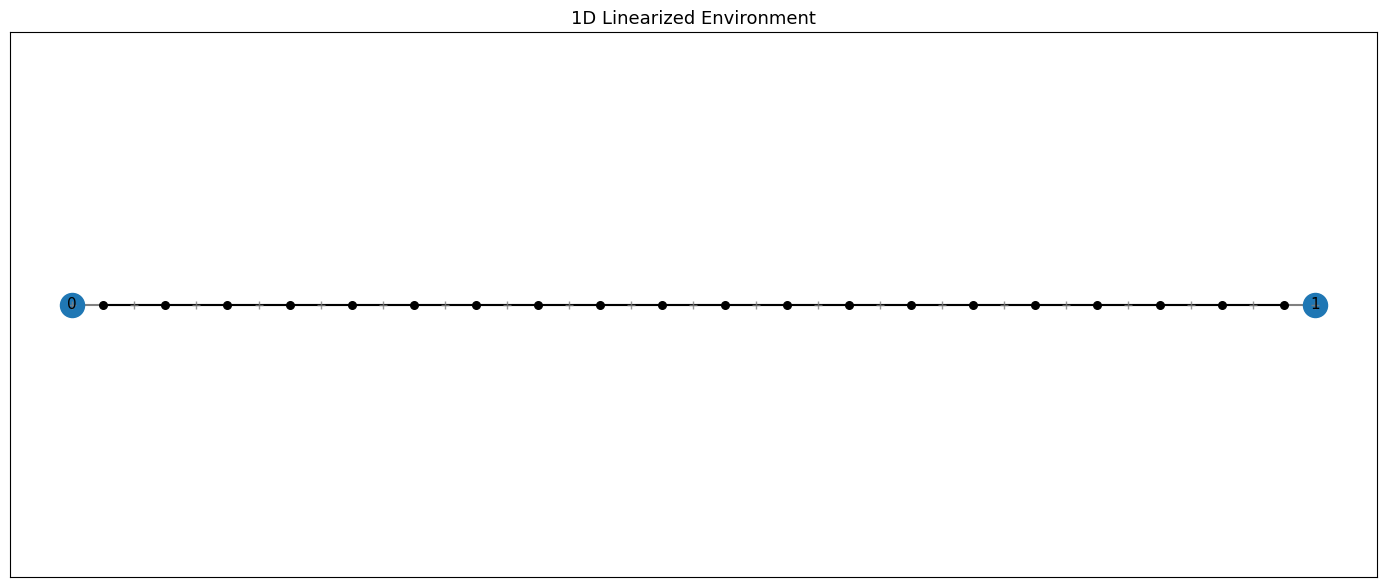


Bin centers shape: (20, 2)
Dimension ranges: ((np.float64(2.5), np.float64(97.5)), (np.float64(0.0), np.float64(0.0)))


In [5]:
if env_1d is not None:
    # Visualize the 1D environment
    fig, ax = plt.subplots(figsize=(14, 6))

    env_1d.plot(ax=ax, show_connectivity=True)

    ax.set_title("1D Linearized Environment")
    plt.tight_layout()
    plt.show()

    print(f"\nBin centers shape: {env_1d.bin_centers.shape}")
    print(f"Dimension ranges: {env_1d.dimension_ranges}")
else:
    print("Skipping visualization (track-linearization not available)")

## Converting Between N-D and Linear Coordinates

1D environments provide special methods:

- **`to_linear(nd_position)`**: Convert 2D position → 1D linear coordinate
- **`linear_to_nd(linear_position)`**: Convert 1D coordinate → 2D position

These methods convert between physical position and the graph's ordered track coordinates. They do not label inbound/outbound trials.

In [6]:
if env_1d is not None and env_1d.is_linearized_track:
    # Map trajectory to linear position
    linear_positions = env_1d.to_linear(linear_track_data)
    projected_positions = env_1d.linear_to_nd(linear_positions)
    np.testing.assert_allclose(projected_positions[:, 0], linear_track_data[:, 0])
    np.testing.assert_allclose(projected_positions[:, 1], 0.0)
    print(
        "Inverse conversion returns the projection onto the track, not off-track noise."
    )

    print(f"Linear positions shape: {linear_positions.shape}")
    print(
        f"Linear position range: [{linear_positions.min():.1f}, {linear_positions.max():.1f}]"
    )

    # Show repeated visits near the same X position
    mid_track_x = 50.0
    mid_indices = np.where(np.abs(linear_track_data[:, 0] - mid_track_x) < 1.0)[0][:10]

    print(f"\nSame X position ({mid_track_x} cm) at different times:")
    for idx in mid_indices[:5]:
        print(
            f"  Time {idx}: 2D pos = {linear_track_data[idx]}, Linear pos = {linear_positions[idx]:.1f}"
        )
else:
    print("Skipping coordinate conversion (track-linearization not available)")

Inverse conversion returns the projection onto the track, not off-track noise.
Linear positions shape: (1000,)
Linear position range: [0.0, 100.0]

Same X position (50.0 cm) at different times:
  Time 0: 2D pos = [50.          0.24835708], Linear pos = 50.0
  Time 100: 2D pos = [49.84276339 -0.70768537], Linear pos = 49.8
  Time 200: 2D pos = [50.31447167  0.17889368], Linear pos = 50.3
  Time 300: 2D pos = [49.52829639 -0.41449751], Linear pos = 49.5
  Time 399: 2D pos = [49.05663476  0.61890816], Linear pos = 49.1


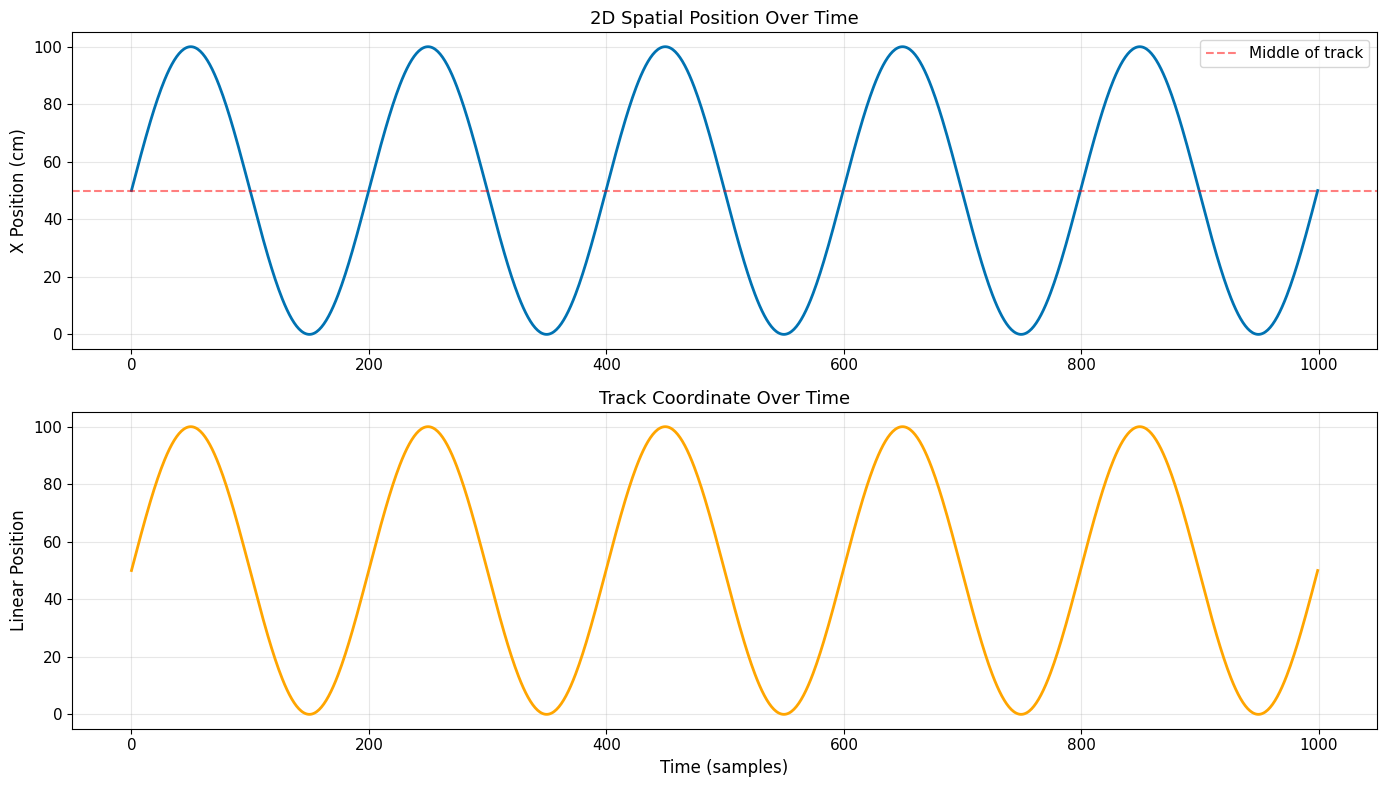


Key insight: Track coordinates decrease during a return traversal.
Use explicit direction labels to separate outbound and inbound firing.


In [7]:
if env_1d is not None and env_1d.is_linearized_track:
    # Visualize linear position over time
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))

    # Top: 2D X position over time
    axes[0].plot(linear_track_data[:, 0], linewidth=2)
    axes[0].set_ylabel("X Position (cm)")
    axes[0].set_title("2D Spatial Position Over Time")
    axes[0].grid(True, alpha=0.3)
    axes[0].axhline(50, color="red", linestyle="--", alpha=0.5, label="Middle of track")
    axes[0].legend()

    # Bottom: 1D linear position over time
    axes[1].plot(linear_positions, linewidth=2, color="orange")
    axes[1].set_xlabel("Time (samples)")
    axes[1].set_ylabel("Linear Position")
    axes[1].set_title("Track Coordinate Over Time")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\nKey insight: Track coordinates decrease during a return traversal.")
    print("Use explicit direction labels to separate outbound and inbound firing.")
else:
    print("Skipping visualization (track-linearization not available)")

## Example 2: Plus Maze

Now let's look at a more complex structure: a plus maze with four arms.

In [8]:
# Create plus maze structure
# Center at (50, 50), arms extend 40 cm in each direction

center = np.array([50.0, 50.0])
arm_length = 40.0

# Define arm endpoints
north_end = center + np.array([0, arm_length])
east_end = center + np.array([arm_length, 0])
south_end = center + np.array([0, -arm_length])
west_end = center + np.array([-arm_length, 0])

# Generate trajectory: start at south, go to center, explore arms
trajectory_segments = [
    # Start at south arm
    (south_end, center),
    # Go to north arm and back
    (center, north_end),
    (north_end, center),
    # Go to east arm and back
    (center, east_end),
    (east_end, center),
    # Go to west arm and back
    (center, west_end),
    (west_end, center),
    # Return to south
    (center, south_end),
]


# Create smooth trajectory
def create_smooth_segment(start, end, n_points=100):
    """Create smooth trajectory between two points."""
    alphas = np.linspace(0, 1, n_points)
    points = np.outer(1 - alphas, start) + np.outer(alphas, end)
    # Add small noise
    points += np.random.randn(n_points, 2) * 0.5
    return points


plus_maze_data = []
for start, end in trajectory_segments:
    segment = create_smooth_segment(start, end, n_points=100)
    plus_maze_data.append(segment)

plus_maze_data = np.vstack(plus_maze_data)

print(f"Generated {len(plus_maze_data)} samples for plus maze")
print("Trajectory visits all 4 arms")

Generated 800 samples for plus maze
Trajectory visits all 4 arms


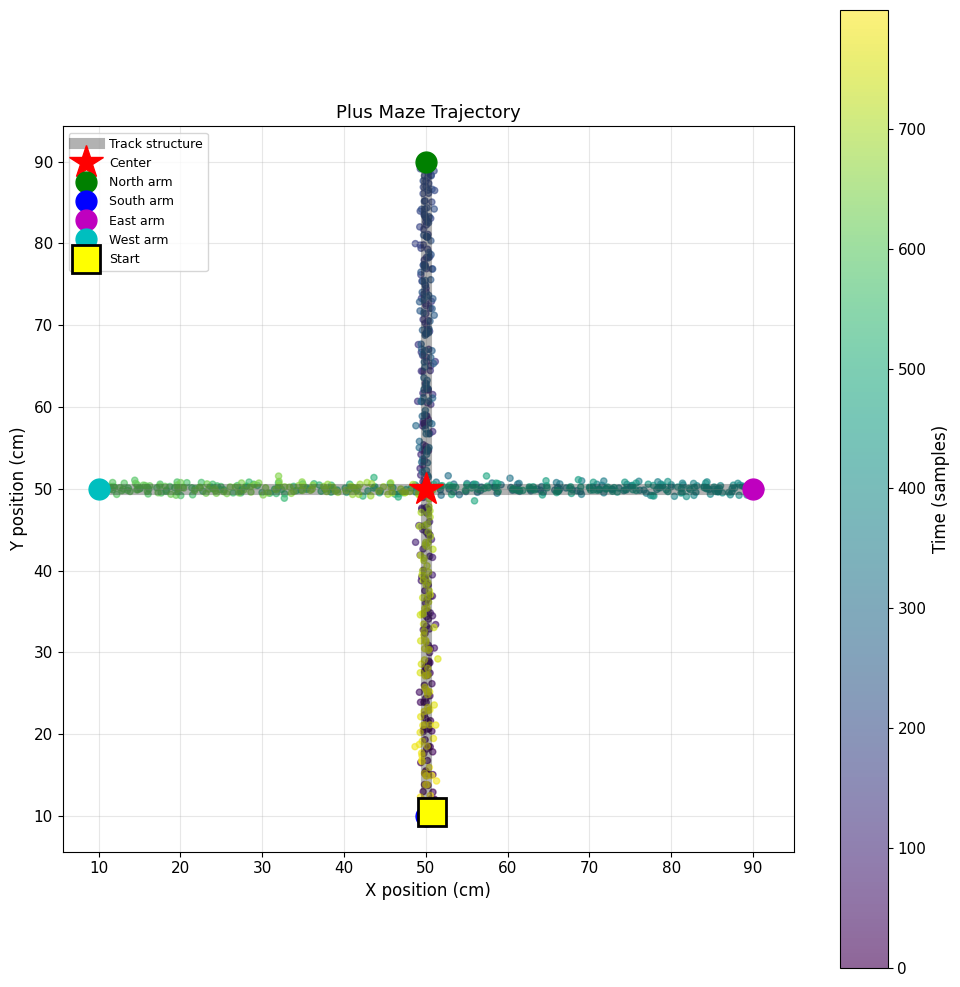

In [9]:
# Visualize plus maze trajectory
fig, ax = plt.subplots(figsize=(10, 10))

# Draw maze structure
ax.plot(
    [center[0], north_end[0]],
    [center[1], north_end[1]],
    "k-",
    linewidth=8,
    alpha=0.3,
    label="Track structure",
)
ax.plot(
    [center[0], south_end[0]], [center[1], south_end[1]], "k-", linewidth=8, alpha=0.3
)
ax.plot(
    [west_end[0], east_end[0]], [center[1], center[1]], "k-", linewidth=8, alpha=0.3
)

# Plot trajectory
scatter = ax.scatter(
    plus_maze_data[:, 0],
    plus_maze_data[:, 1],
    c=np.arange(len(plus_maze_data)),
    cmap="viridis",
    s=20,
    alpha=0.6,
)

# Mark center and arm endpoints
ax.plot(center[0], center[1], "r*", markersize=25, label="Center")
ax.plot(north_end[0], north_end[1], "go", markersize=15, label="North arm")
ax.plot(south_end[0], south_end[1], "bo", markersize=15, label="South arm")
ax.plot(east_end[0], east_end[1], "mo", markersize=15, label="East arm")
ax.plot(west_end[0], west_end[1], "co", markersize=15, label="West arm")

# Mark start
ax.plot(
    plus_maze_data[0, 0],
    plus_maze_data[0, 1],
    "ks",
    markersize=20,
    label="Start",
    markeredgewidth=2,
    markerfacecolor="yellow",
)

ax.set_xlabel("X position (cm)")
ax.set_ylabel("Y position (cm)")
ax.set_title("Plus Maze Trajectory")
ax.set_aspect("equal")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax, label="Time (samples)")
plt.tight_layout()
plt.show()

### Creating Plus Maze Environment with Graph

For complex mazes, you can provide an explicit track graph structure:

In [10]:
# Define track graph structure
# Nodes are named locations, edges are track segments

track_graph = nx.Graph()

# Add nodes with 2D positions
track_graph.add_node("center", pos=center)
track_graph.add_node("north", pos=north_end)
track_graph.add_node("south", pos=south_end)
track_graph.add_node("east", pos=east_end)
track_graph.add_node("west", pos=west_end)

# Add edges (track segments) with sequential edge_ids
track_graph.add_edge("center", "north", edge_id=0)
track_graph.add_edge("center", "south", edge_id=1)
track_graph.add_edge("center", "east", edge_id=2)
track_graph.add_edge("center", "west", edge_id=3)

# Add distance attributes to edges (required by GraphLayout)
for u, v in track_graph.edges():
    pos_u = np.array(track_graph.nodes[u]["pos"])
    pos_v = np.array(track_graph.nodes[v]["pos"])
    track_graph.edges[u, v]["distance"] = np.linalg.norm(pos_v - pos_u)

print(
    f"Track graph: {track_graph.number_of_nodes()} nodes, {track_graph.number_of_edges()} edges"
)
print(f"Nodes: {list(track_graph.nodes())}")

Track graph: 5 nodes, 4 edges
Nodes: ['center', 'north', 'south', 'east', 'west']


In [11]:
# Define edge order for plus maze (order in which edges are traversed)
# For a plus maze, we traverse all 4 arms from the center
plus_maze_edge_order = [
    ("center", "north"),
    ("center", "south"),
    ("center", "east"),
    ("center", "west"),
]

# Create 1D environment for plus maze
env_plus = Environment.from_graph(
    graph=track_graph,
    edge_order=plus_maze_edge_order,
    edge_spacing=0.0,  # No spacing between edges
    bin_size=5.0,
    name="PlusMaze",
)
env_plus.units = "cm"

print("Plus Maze 1D Environment Created!")
print(env_plus.info())

Plus Maze 1D Environment Created!
Environment Information

Name: PlusMaze
Layout Type: Graph
Dimensions: 2
Number of Bins: 32

Spatial Extent:
  Dimension 0: [12.50, 87.50] (range: 75.00)
  Dimension 1: [12.50, 87.50] (range: 75.00)

Bin Sizes:
  Dimension 0: 5.00

Regions: None

Linearization: Available (1D environment)



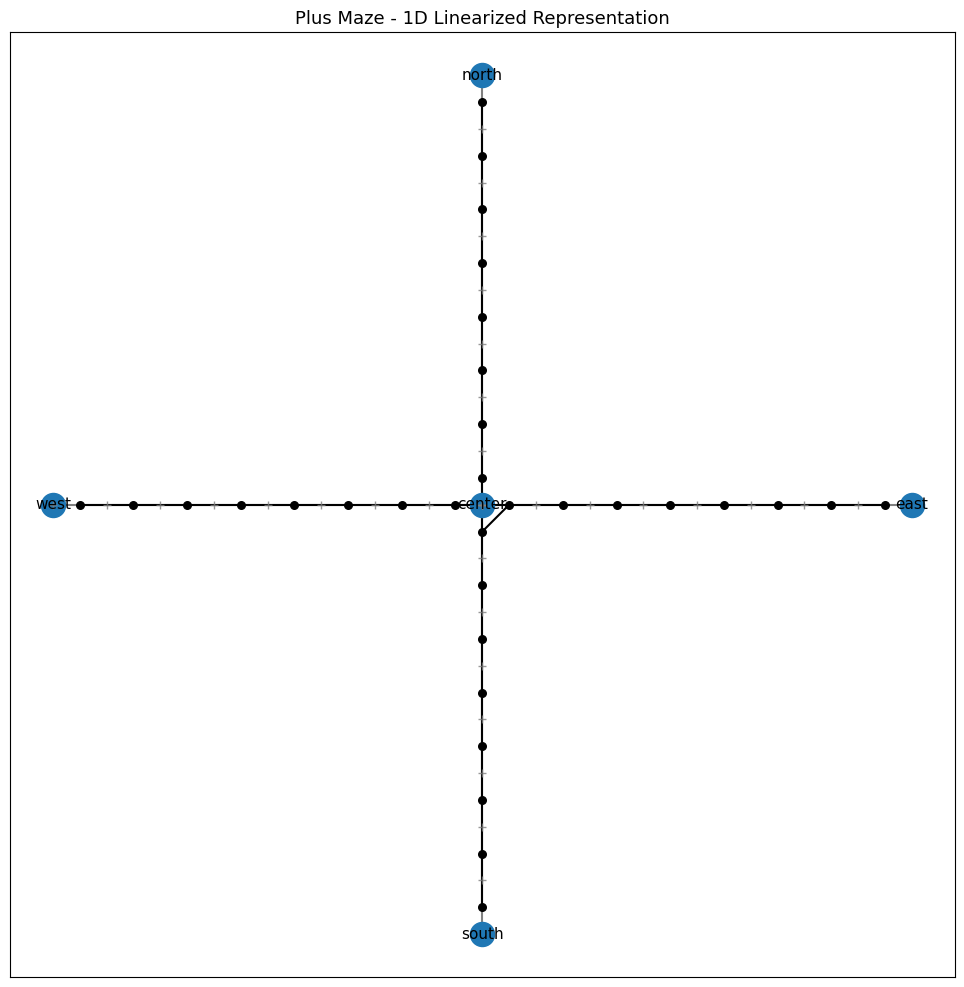


Note: Edge order arranges the graph's track-coordinate axis.
It does not supply a trial or direction label at the center.


In [12]:
# Visualize the linearized plus maze
fig, ax = plt.subplots(figsize=(12, 10))

env_plus.plot(ax=ax, show_connectivity=True)

ax.set_title("Plus Maze - 1D Linearized Representation")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

print("\nNote: Edge order arranges the graph's track-coordinate axis.")
print("It does not supply a trial or direction label at the center.")

## Why Linearization Matters: Neural Analysis Example

Let's demonstrate why linearization is crucial for neural analysis on tracks.

In [13]:
# Simulate a place cell that fires on the north arm only
def simulate_trajectory_specific_cell(
    position_data, arm_start, arm_end, field_size=10.0
):
    """
    Simulate a neuron that fires only when moving toward a specific arm.

    Parameters
    ----------
    position_data : ndarray, shape (n_samples, 2)
        Position trajectory.
    arm_start : array-like, shape (2,)
        Start of arm (center).
    arm_end : array-like, shape (2,)
        End of arm.
    field_size : float
        Spatial scale of place field.

    Returns
    -------
    spike_counts : ndarray, shape (n_samples,)
        Spikes at each position.
    """
    # Check if position is on the arm and moving in correct direction
    arm_direction = arm_end - arm_start
    arm_direction = arm_direction / np.linalg.norm(arm_direction)

    # Field center is 2/3 along the arm
    field_center = arm_start + 0.67 * (arm_end - arm_start)

    spike_counts = np.zeros(len(position_data))

    for i in range(1, len(position_data)):
        # Distance to field center
        distance = np.linalg.norm(position_data[i] - field_center)

        # Movement direction
        movement = position_data[i] - position_data[i - 1]
        if np.linalg.norm(movement) > 0.1:
            movement_dir = movement / np.linalg.norm(movement)

            # Check if moving toward arm end
            alignment = np.dot(movement_dir, arm_direction)

            if alignment > 0.5 and distance < field_size:
                # Fire based on distance
                firing_rate = 30.0 * np.exp(-(distance**2) / (2 * field_size**2))
                spike_counts[i] = np.random.poisson(firing_rate * 0.05)

    return spike_counts


# Simulate a cell that fires only when going TO north arm (not returning)
north_cell_spikes = simulate_trajectory_specific_cell(
    plus_maze_data, center, north_end, field_size=15.0
)

print(f"Generated {north_cell_spikes.sum()} spikes")
print(f"Mean firing rate: {north_cell_spikes.mean() / 0.05:.2f} Hz")

Generated 70.0 spikes
Mean firing rate: 1.75 Hz


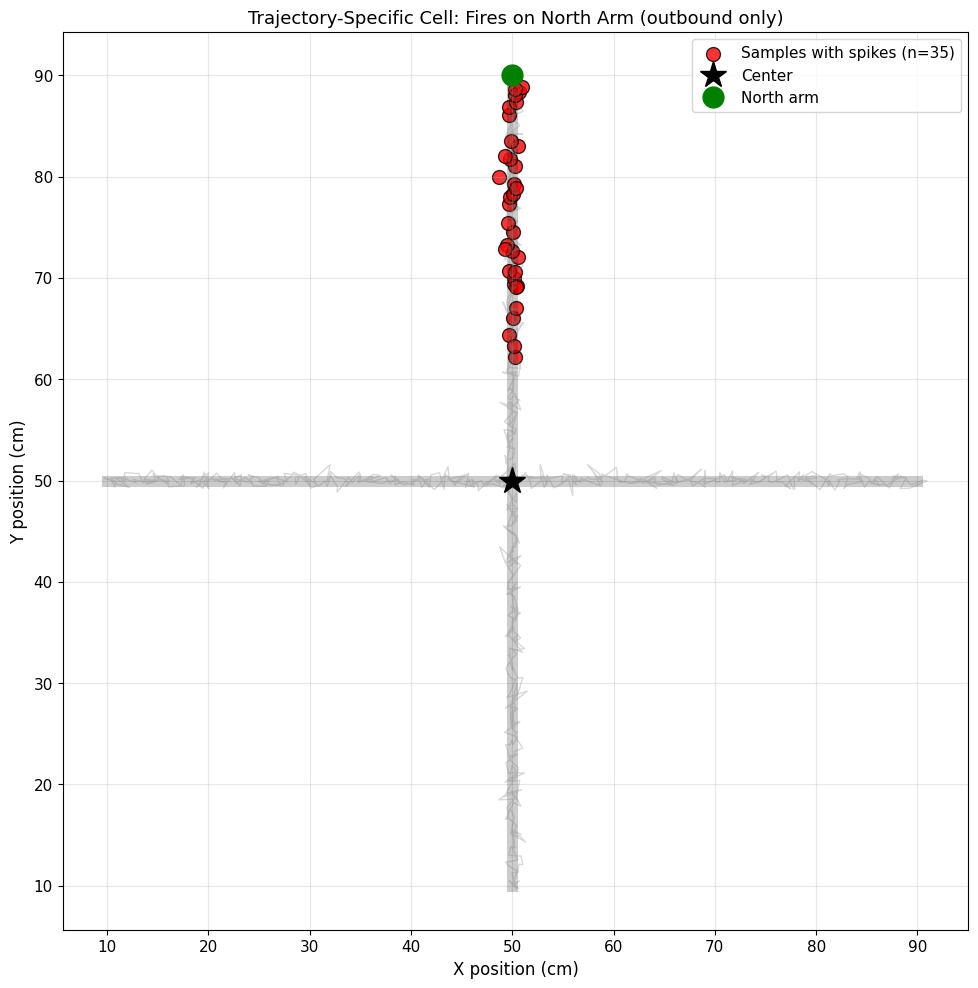


Notice: Cell fires specifically when animal moves toward north arm
But NOT when returning from north arm through the same physical space!


In [14]:
# Visualize spikes on 2D trajectory
fig, ax = plt.subplots(figsize=(10, 10))

# Draw maze structure
ax.plot(
    [center[0], north_end[0]], [center[1], north_end[1]], "k-", linewidth=8, alpha=0.2
)
ax.plot(
    [center[0], south_end[0]], [center[1], south_end[1]], "k-", linewidth=8, alpha=0.2
)
ax.plot(
    [west_end[0], east_end[0]], [center[1], center[1]], "k-", linewidth=8, alpha=0.2
)

# Plot trajectory
ax.plot(plus_maze_data[:, 0], plus_maze_data[:, 1], "gray", alpha=0.3, linewidth=1)

# Highlight spike locations
spike_indices = np.where(north_cell_spikes > 0)[0]
spike_positions = plus_maze_data[spike_indices]

ax.scatter(
    spike_positions[:, 0],
    spike_positions[:, 1],
    c="red",
    s=100,
    alpha=0.8,
    marker="o",
    edgecolors="black",
    linewidth=1,
    label=f"Samples with spikes (n={len(spike_indices)})",
)

ax.plot(center[0], center[1], "k*", markersize=20, label="Center")
ax.plot(north_end[0], north_end[1], "go", markersize=15, label="North arm")

ax.set_xlabel("X position (cm)")
ax.set_ylabel("Y position (cm)")
ax.set_title("Trajectory-Specific Cell: Fires on North Arm (outbound only)")
ax.set_aspect("equal")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nNotice: Cell fires specifically when animal moves toward north arm")
print("But NOT when returning from north arm through the same physical space!")

### Pooled Spatial Maps Average Across Directions

A map computed without direction labels pools outbound and inbound occupancy. This happens on both a 2D grid and a graph track.

In [15]:
# Create a 2D environment for a direction-pooled comparison
env_2d = Environment.from_samples(
    positions=plus_maze_data, bin_size=8.0, name="PlusMaze2D", units="cm"
)

# Map to bins
bin_indices_2d = env_2d.bin_at(plus_maze_data)

# Compute firing rate
spike_counts_per_bin = np.bincount(
    bin_indices_2d[bin_indices_2d >= 0],
    weights=north_cell_spikes[bin_indices_2d >= 0],
    minlength=env_2d.n_bins,
)

occupancy_per_bin = (
    np.bincount(bin_indices_2d[bin_indices_2d >= 0], minlength=env_2d.n_bins) * 0.05
)

firing_rate_2d = np.divide(
    spike_counts_per_bin,
    occupancy_per_bin,
    where=occupancy_per_bin > 0,
    out=np.full_like(spike_counts_per_bin, np.nan, dtype=float),
)

print(f"2D firing rate map: {env_2d.n_bins} bins")
print(f"Peak firing rate: {firing_rate_2d.max():.2f} Hz")

2D firing rate map: 44 bins
Peak firing rate: 18.46 Hz


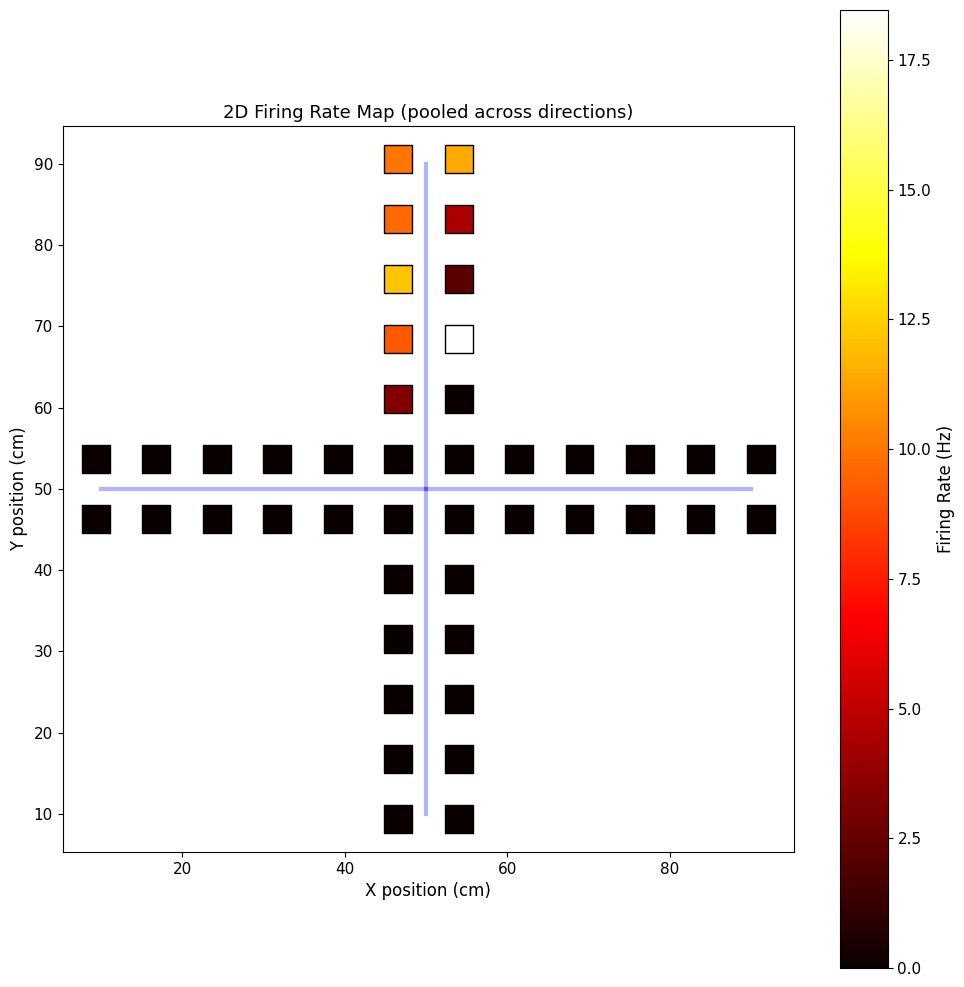


Problem: 2D map averages over outbound and inbound journeys
Direction-dependent firing needs a separate label, regardless of layout.


In [16]:
# Visualize the direction-pooled 2D firing rate
fig, ax = plt.subplots(figsize=(10, 10))

# Plot firing rate
active_bins = np.isfinite(firing_rate_2d)
scatter = ax.scatter(
    env_2d.bin_centers[active_bins, 0],
    env_2d.bin_centers[active_bins, 1],
    c=firing_rate_2d[active_bins],
    vmin=0,
    s=400,
    cmap="hot",
    marker="s",
    edgecolors="black",
    linewidth=1,
)

# Draw maze structure
ax.plot(
    [center[0], north_end[0]], [center[1], north_end[1]], "b-", linewidth=3, alpha=0.3
)
ax.plot(
    [center[0], south_end[0]], [center[1], south_end[1]], "b-", linewidth=3, alpha=0.3
)
ax.plot(
    [west_end[0], east_end[0]], [center[1], center[1]], "b-", linewidth=3, alpha=0.3
)

ax.set_xlabel("X position (cm)")
ax.set_ylabel("Y position (cm)")
ax.set_title("2D Firing Rate Map (pooled across directions)")
ax.set_aspect("equal")
plt.colorbar(scatter, ax=ax, label="Firing Rate (Hz)")
plt.tight_layout()
plt.show()

print("\nProblem: 2D map averages over outbound and inbound journeys")
print("Direction-dependent firing needs a separate label, regardless of layout.")

### Graph Coordinates Also Pool Directions Without Labels

The graph representation follows the track geometry. The calculation below still pools directions because it uses no direction labels; a higher peak can reflect different binning rather than recovered direction dependence.

In [17]:
if env_plus is not None and env_plus.is_linearized_track:
    # Map to 1D bins
    bin_indices_1d = env_plus.bin_at(plus_maze_data)

    # Compute firing rate in 1D
    spike_counts_per_bin_1d = np.bincount(
        bin_indices_1d[bin_indices_1d >= 0],
        weights=north_cell_spikes[bin_indices_1d >= 0],
        minlength=env_plus.n_bins,
    )

    occupancy_per_bin_1d = (
        np.bincount(bin_indices_1d[bin_indices_1d >= 0], minlength=env_plus.n_bins)
        * 0.05
    )

    firing_rate_1d = np.divide(
        spike_counts_per_bin_1d,
        occupancy_per_bin_1d,
        where=occupancy_per_bin_1d > 0,
        out=np.full_like(spike_counts_per_bin_1d, np.nan, dtype=float),
    )

    print(f"1D firing rate map: {env_plus.n_bins} bins")
    print(f"Peak firing rate: {firing_rate_1d.max():.2f} Hz")
    print("\nThis graph map also pools outbound and inbound occupancy.")
else:
    print("Skipping 1D analysis (track-linearization not available)")

1D firing rate map: 32 bins
Peak firing rate: 13.60 Hz

This graph map also pools outbound and inbound occupancy.


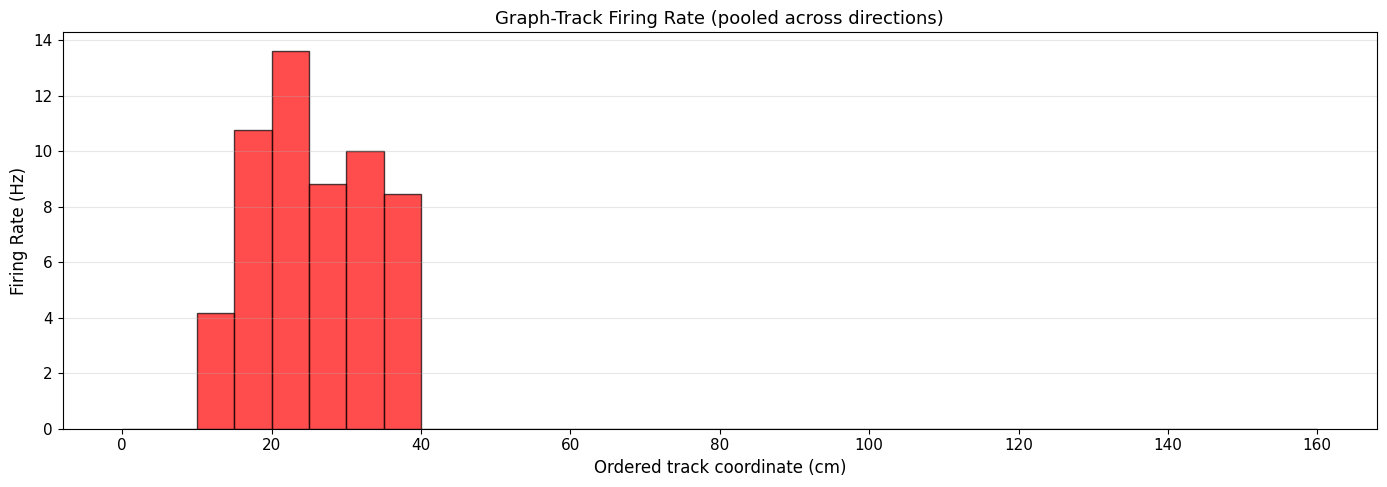


Graph geometry localizes the field to track bins.
Outbound and inbound firing are still pooled in this map.


In [18]:
if env_plus is not None and env_plus.is_linearized_track:
    # Visualize 1D firing rate
    fig, ax = plt.subplots(figsize=(14, 5))

    # Get linear positions
    linear_pos = env_plus.to_linear(plus_maze_data)

    # Plot firing rate as function of linear position
    bin_linear_positions = env_plus.to_linear(env_plus.bin_centers)

    ax.bar(
        bin_linear_positions,
        firing_rate_1d,
        width=5.0,
        color="red",
        alpha=0.7,
        edgecolor="black",
        linewidth=1,
    )

    ax.set_xlabel("Ordered track coordinate (cm)")
    ax.set_ylabel("Firing Rate (Hz)")
    ax.set_title("Graph-Track Firing Rate (pooled across directions)")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\nGraph geometry localizes the field to track bins.")
    print("Outbound and inbound firing are still pooled in this map.")
else:
    print("Skipping visualization (track-linearization not available)")

## Direction-Specific Fields Need Explicit Trial Labels

This complete example combines an explicit graph, out-and-back trials and direction labels. Geometric coordinates repeat on the return path, while the two direction-conditioned maps recover their separately planted centers within one 5 cm bin. The same recipe is executed in the [workflows guide](https://edeno.github.io/neurospatial/user-guide/workflows/#direction-specific-fields-on-a-graph-track).

home→goal: planted 60.0 cm, recovered 57.5 cm
goal→home: planted 40.0 cm, recovered 37.5 cm


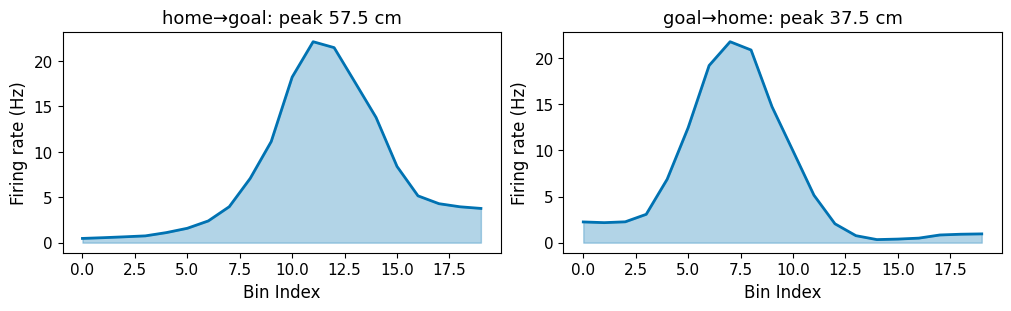

In [19]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from shapely.geometry import Polygon

from neurospatial import Environment
from neurospatial.behavior import goal_pair_direction_labels, segment_trials
from neurospatial.encoding import compute_directional_place_fields
from neurospatial.simulation import generate_poisson_spikes

# A 100 cm track: graph coordinates describe geometry, not running direction.
graph = nx.Graph()
graph.add_node(0, pos=(0.0, 0.0))
graph.add_node(1, pos=(100.0, 0.0))
graph.add_edge(0, 1, distance=100.0)
env = Environment.from_graph(graph, edge_order=[(0, 1)], edge_spacing=0.0, bin_size=5.0)
env.units = "cm"
repeated = np.array([[25.0, 0.0], [50.0, 0.0], [75.0, 0.0], [50.0, 0.0], [25.0, 0.0]])
np.testing.assert_allclose(env.to_linear(repeated), repeated[:, 0])
repeated_bins = env.bin_at(repeated)
assert repeated_bins[0] == repeated_bins[-1] and repeated_bins[1] == repeated_bins[-2]

# Six out-and-back cycles in 60 seconds, with different planted field centers.
times = np.arange(0.0, 60.0, 0.05)
phase = (times % 10.0) / 10.0
x = 10.0 + 80.0 * (1.0 - np.abs(2.0 * phase - 1.0))
positions = np.column_stack([x, np.zeros_like(x)])
planted_center = np.where(phase < 0.5, 60.0, 40.0)
intensity = 0.5 + 25.0 * np.exp(-0.5 * ((x - planted_center) / 10.0) ** 2)
spikes = generate_poisson_spikes(intensity, times, seed=7)

# Explicit trials supply the direction labels; both maps use the same graph.
env.regions.add("home", polygon=Polygon([(-1, -5), (15, -5), (15, 5), (-1, 5)]))
env.regions.add("goal", polygon=Polygon([(85, -5), (101, -5), (101, 5), (85, 5)]))
position_bins = env.bin_sequence(times, positions, dedup=False)
outbound = segment_trials(
    position_bins, times, env, start_region="home", end_regions=["goal"]
)
inbound = segment_trials(
    position_bins, times, env, start_region="goal", end_regions=["home"]
)
labels = goal_pair_direction_labels(times, outbound + inbound)
fields = compute_directional_place_fields(env, spikes, times, positions, labels)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for ax, label, truth in zip(
    axes, ["home→goal", "goal→home"], [60.0, 40.0], strict=True
):
    field = fields.firing_rates[label]
    recovered = env.bin_centers[np.nanargmax(field), 0]
    assert abs(recovered - truth) <= 5.0  # Recover each planted center within one bin.
    env.plot_field(field, ax=ax, colorbar_label="Firing rate (Hz)")
    ax.set_title(f"{label}: peak {recovered:.1f} cm")
    print(f"{label}: planted {truth:.1f} cm, recovered {recovered:.1f} cm")
plt.show()

## When to Use 1D vs N-D Environments

| Use 1D (GraphLayout) | Use N-D (GridLayout) |
|---------------------|---------------------|
| Linear tracks | Open field arenas |
| Mazes with defined paths | Water mazes |
| Track-based tasks | Free exploration |
| Coordinates along constrained paths | Coordinates in continuous arenas |
| Sequence detection | Grid cell analysis |
| Theta sequences, replay | Head direction independence |

**Key question**: Is movement constrained to an explicit track graph or an open arena?
- **Track geometry** → Use GraphLayout coordinates
- **Open arena** → Use N-D grids
- **Direction or trial matters** → Supply explicit labels with either layout

## Checking if Environment is 1D

In [20]:
# Always check before calling linearization methods!


def safe_linearize(env, position):
    """
    Safely convert to linear position.

    Parameters
    ----------
    env : Environment
        Environment instance.
    position : ndarray
        Position data.

    Returns
    -------
    linear_position : ndarray or None
        Linear position if 1D, None otherwise.
    """
    if env.is_linearized_track:
        return env.to_linear(position)
    else:
        print(f"Warning: {env.name} is not 1D (is {env.n_dims}D)")
        print("Use bin_at() instead for spatial binning")
        return None


# Test
print("Testing 2D environment:")
result = safe_linearize(env_2d, plus_maze_data[:10])

if env_plus is not None:
    print("\nTesting 1D environment:")
    result = safe_linearize(env_plus, plus_maze_data[:10])
    print(f"Linear positions: {result}")

Testing 2D environment:
Use bin_at() instead for spatial binning

Testing 1D environment:
Linear positions: [79.53768316 79.91942798 78.9951765  78.47029289 78.65145599 77.88099818
 77.92035148 77.07276178 77.00961968 76.15155339]


## Common Pitfalls

### Pitfall 1: Calling linearization methods on N-D environments

In [21]:
# ✗ WRONG - Don't call to_linear() on non-1D environments
try:
    linear = env_2d.to_linear(plus_maze_data[:10])
except AttributeError as e:
    print(f"Error: {e}")
    print("\nAlways check env.is_linearized_track before calling to_linear()!")

# ✓ CORRECT
if env_2d.is_linearized_track:
    linear = env_2d.to_linear(plus_maze_data[:10])
else:
    print("Using spatial binning instead")
    bins = env_2d.bin_at(plus_maze_data[:10])

Error: to_linear() is only available for 1D environments (GraphLayout). This environment is 2D. Use bin_at() to map positions to bins for N-D environments.

Always check env.is_linearized_track before calling to_linear()!
Using spatial binning instead


### Pitfall 2: Pooling directions when firing depends on direction

Both grids and graph tracks pool directions unless the analysis receives explicit direction or trial labels. See the joined graph-track recipe below and [directional place fields](21_directional_place_fields.ipynb).

### Pitfall 3: Omitting the graph for a constrained track

`from_graph()` requires an explicit graph, including edge distances. Specify branch geometry and edge order deliberately; coordinates alone do not encode the animal's trial choice.

### Pitfall 4: Treating geometric coordinates as a direction label

On a single-edge track, opposite traversals revisit the same coordinates and bins. On branched graphs, consult the graph/projection settings rather than assuming universal direction separation or monotonic coordinates.

## Key Takeaways

1. **1D linearization** maps 2D/3D positions onto a 1D track coordinate
2. **GraphLayout** creates 1D linearized environments (requires `track-linearization`)
3. **Use `from_graph()`** with an explicit graph and edge ordering
4. **Geometry and direction differ**: Repeated track locations share bins; direction-conditioned fields require explicit labels
5. **Essential for track tasks**: Plus mazes, T-mazes, linear tracks, figure-8s
6. **Check `env.is_linearized_track`** before calling linearization methods
7. **Methods**:
   - `to_linear(nd_position)` - Convert to 1D
   - `linear_to_nd(linear_position)` - Convert back to N-D
8. **Benefits**: Track geometry and distances; combine with trial labels for direction-conditioned fields

## Next Steps

You can now combine the geometry, regions and explicit labels introduced here:

1. ✓ **Basics** (notebook 01) - Creating environments, spatial queries
2. ✓ **Layout engines** (notebook 02) - Regular, hexagonal, polygon-bounded
3. ✓ **Morphological operations** (notebook 03) - Handling sparse data
4. ✓ **Regions** (notebook 04) - Defining and analyzing zones
5. ✓ **Linearization** (notebook 05) - 1D track analysis

Continue to [06: composite environments](06_composite_environments.ipynb)
for multiple spaces, [08: spike-field basics](08_spike_field_basics.ipynb)
for timestamped spike analysis, or [21: directional fields](21_directional_place_fields.ipynb)
for a fuller direction-conditioned analysis.

## Exercises (Optional)

1. Create a figure-8 maze with explicit track graph
2. Simulate a place cell that fires on one arm but not others
3. Compare 2D vs 1D occupancy normalization for the same cell
4. Create a W-track environment and analyze directional place fields